In [2]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import cv2
import torch

In [9]:
import pandas as pd
pathcsv = "/scratch/anirudhkaushik/ADNI1_Complete_DataSplits.csv"

df = pd.read_csv(pathcsv)
# find all cases which have Age=74, Group=MCI and Visit=sc
# get the subject id for these subjects
# get the corresponding visit=m06 for these subjects
df_filtered = df[(df['Age'] == 74) & (df['Group'] == 'MCI') & (df['Visit'] == 'sc')]
# get the subject id for these subjects
subject_ids = df_filtered['Subject'].tolist()
# get the corresponding visit=m06 for these subjects
df_m06 = df[(df['Visit'] == 'm06') & (df['Subject'].isin(subject_ids))]

# get list of file paths from File_Path for these cases
file_paths = df_m06['File_Path'].tolist()

(128, 128, 128)


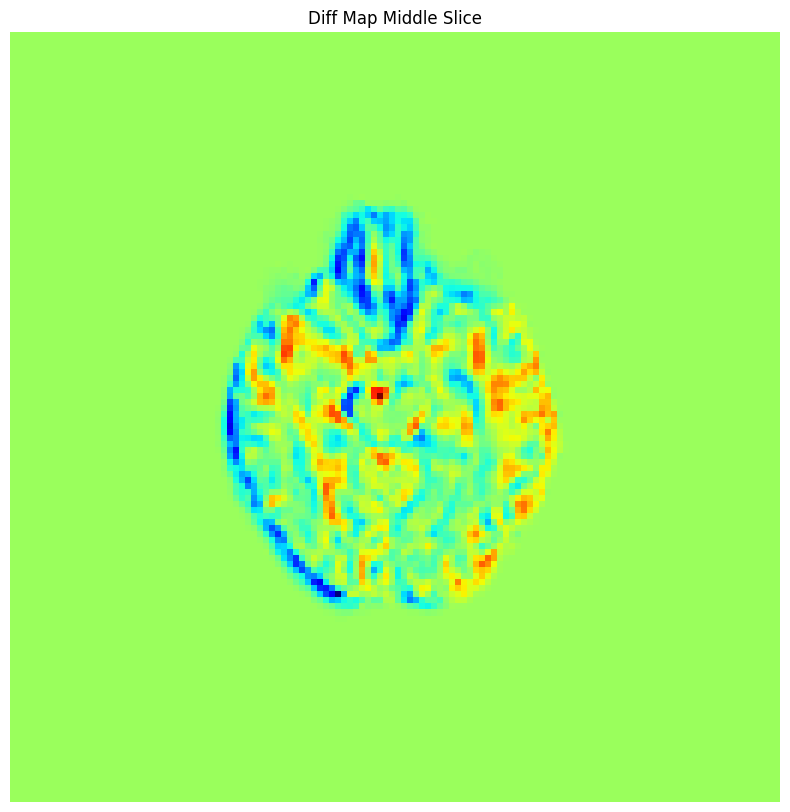

In [9]:
# adjust so that axial view isnt squashed
# get axial aspect ratio
path = "/home2/anirudhkaushik/SYNBADD/results/SYNBADD_128_8_1e-05_0.0_2025-04-08_08-04-54_ADNI_all_longitudinal_DAFT_Resnet_SVF_2Layer_Vanilla_Fold2/volume_class1.0_reg74.0_tp1.0_Past_Future_747760.nii.gz"
path2 = "/home2/anirudhkaushik/SYNBADD/results/SYNBADD_128_8_1e-05_0.0_2025-04-08_10-10-54_ADNI_all_prev_only_DAFT_Resnet_SVF_2Layer_OnlyPast_Fold2/volume_class1.0_reg74.0_tp1.0_Past_747760.nii.gz"

img = nib.load(path)
img2 = nib.load(path2)

img_data = img.get_fdata()
img_data2 = img2.get_fdata()

# calculate a difference map
diff_map = img_data2 - img_data

# save the diff map
diff_img = nib.Nifti1Image(diff_map, img.affine)
nib.save(diff_img, '/home2/anirudhkaushik/SYNBADD/results/diff_map.nii.gz')

# load diff img
diff_img = nib.load('/home2/anirudhkaushik/SYNBADD/results/diff_map.nii.gz')
diff_img_data = diff_img.get_fdata()
print(diff_img_data.shape)

# visualize the diff map
# get the middle slice of the diff map

plt.figure(figsize=(10, 10))
plt.imshow(diff_img_data[:, :, diff_img_data.shape[2] // 2], cmap='jet')
plt.title('Diff Map Middle Slice')
plt.axis('off')
plt.show()

In [17]:
model = torch.hub.load('mateuszbuda/brain-segmentation-pytorch', 'unet',
    in_channels=3, out_channels=1, init_features=32, pretrained=True)

/home2/anirudhkaushik/miniconda3/envs/pytorch/lib/python3.10/site-packages/torch/hub.py:294: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(
Downloading: "https://github.com/mateuszbuda/brain-segmentation-pytorch/zipball/master" to /home2/anirudhkaushik/.cache/torch/hub/master.zip
Downloading: "https://github.com/mateuszbuda/brain-segmentation-pytorch/releases/download/v1.0/unet-e012d006.pt" to /home2/anirudhkaushik/.cache/torch/hub/checkpoints/unet-e012d0

In [61]:
from torchvision import transforms

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=0, std=1),
])

class Dataset(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = nib.load(self.paths[idx])
        img = img.get_fdata()[:, 100, :]
        img = cv2.resize(img, (256, 256))
        img = img/img.max()
        img = (img * 255).astype(np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        # convert to byte
        img = preprocess(img)
        return img
    
dataset = Dataset([path])
loader = torch.utils.data.DataLoader(dataset, batch_size=1, shuffle=False)


(256, 256)


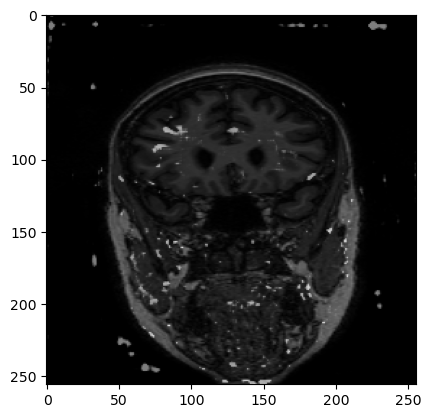

In [68]:
for img in loader:
    pred = model(img)
    pred = pred[0, 0].detach().numpy()
    print(pred.shape)
    # show as a segmentation mask on top of the original image
    plt.imshow(img[0].permute(1,2,0).detach().numpy())
    plt.imshow(pred, cmap='gray', alpha=0.5)

    plt.show()
    break


In [3]:
import pydicom
import glob
import numpy as np
for file in glob.glob("/ssd_scratch/cvit/anirudhkaushik/PET/ADNI/*/*/*/*"):

    img = []
    for dcm in glob.glob(file + "/*.dcm"):
        i = pydicom.dcmread(dcm).pixel_array
        img.append(i)

    img = np.array(img)
    img = np.transpose(img, (1,2,0))
    break

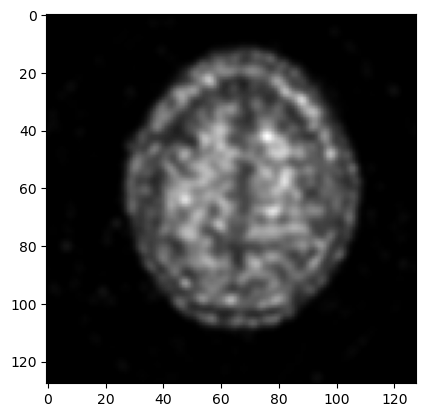

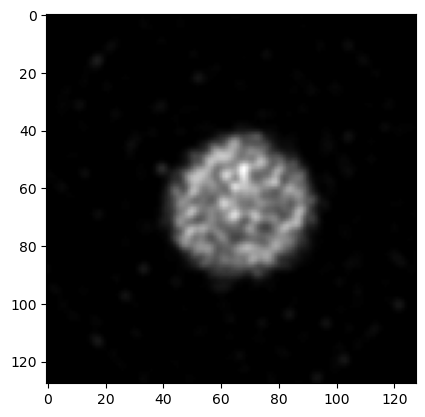

In [20]:
import matplotlib.pyplot as plt
img = img/img.max()
img = img/img.max()

img = (img * 255).astype(np.uint8)

plt.imshow(img[:,:,200],cmap='gray' )
plt.show()
plt.imshow(img[:,:,-1],cmap='gray' )
plt.show()


In [8]:
import ants
import nibabel as nib
import numpy as np
import os
import matplotlib.pyplot as plt
import torch

In [ ]:
image1 = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739949019_S67612_I150177_padded_transposed_padded_transposed.nii.gz"
image2 = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739949020_S54061_I123685_padded_transposed_padded_transposed.nii.gz"


target_ants = ants.image_read(image1)
generated_ants = ants.image_read(image2)

print(target_ants.shape)

# print metadata
print(target_ants.spacing)

lddmm_result = ants.registration(
                fixed=target_ants,
                moving=generated_ants,
                type_of_transform='SyN',  # LDDMM-style diffeomorphic
            )

# Compute intensity loss (e.g., MSE)
registered_ants = lddmm_result["warpedmovout"]

# Compute Jacobian determinant
jacobian_det_ants = ants.create_jacobian_determinant_image(
    target_ants, lddmm_result["fwdtransforms"][0], do_log=True
)
jacobian_det_tensor = torch.tensor(jacobian_det_ants.numpy())
jacobian_loss = torch.mean(torch.abs(jacobian_det_tensor))  # Penalizes unrealistic deformations

plt.imshow(jacobian_det_ants.numpy()[:,:,50])
plt.show()

(128, 128, 128)
(0.9475276470184326, 0.944205105304718, 1.2023072242736816)
